In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from matplotlib import pyplot as plt

In [35]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
tas_z = xr.open_dataset("../data/features/tas_z.nc")
smtop_z = xr.open_dataset("../data/features/smtop_z.nc")
smmid_z = xr.open_dataset("../data/features/smmid_z.nc")
smlow_z = xr.open_dataset("../data/features/smlow_z.nc")
pr_z = xr.open_dataset("../data/features/pr_z.nc")
dtr_z = xr.open_dataset("../data/features/dtr_z.nc")

In [23]:
# load feature ds
feature_ds = xr.open_dataset("../data/features/feature_ds.nc").load()

In [4]:
tas_z.var

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 570kB
Dimensions:    (region_id: 79, year: 25, month: 12, dekad: 3)
Coordinates:
  * region_id  (region_id) int64 632B 1 2 3 4 5 6 7 8 ... 73 74 75 76 77 78 79
  * year       (year) int32 100B 2001 2002 2003 2004 ... 2022 2023 2024 2025
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Data variables:
    tas_z      (region_id, year, month, dekad) float64 569kB ...>

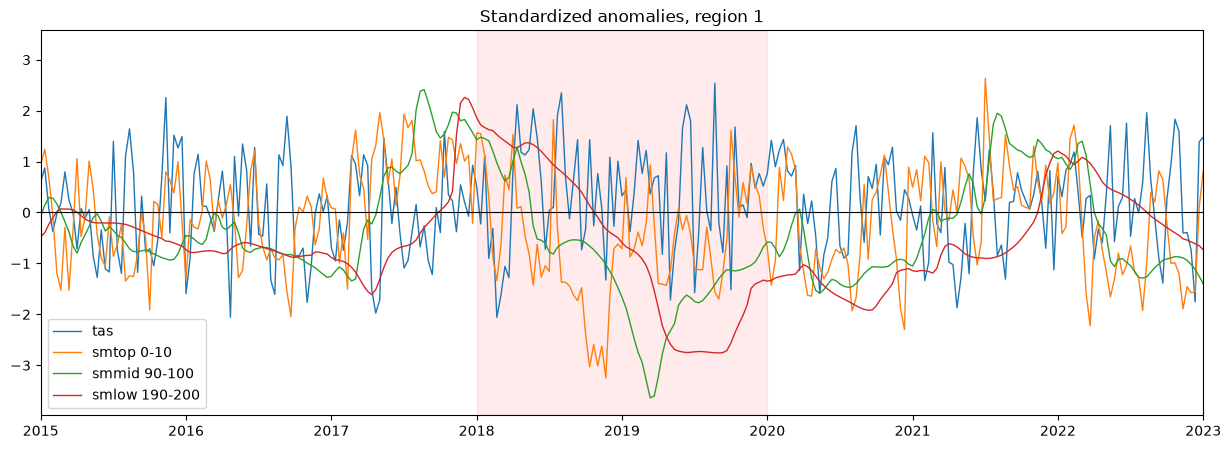

In [ ]:

# plot from ChatGPT 
def to_series(da, rid):
    selected = da.sel(region_id=rid)

    if isinstance(selected, xr.Dataset):
        # If it's a Dataset, select the variable to plot
        if len(selected.data_vars) == 1:
            selected = selected[next(iter(selected.data_vars))]
        else:
            raise ValueError(
                f"Expected one variable, found: {list(selected.data_vars)}"
            )

    df = selected.to_dataframe(name="z").reset_index()

    df["t"] = (
        df["year"]
        + (df["month"] - 1) / 12
        + (df["dekad"] - 1) / 36
    )

    return df.sort_values("t")


rid = 1

fig, ax = plt.subplots(figsize=(15, 5))

for da, label in [
    (tas_z, "tas"),
    (smtop_z, "smtop 0-10"),
    (smmid_z, "smmid 90-100"),
    (smlow_z, "smlow 190-200"),
]:
    s = to_series(da, rid)
    ax.plot(s["t"], s["z"], label=label, lw=1)

ax.axhline(0, color="k", lw=0.8)
ax.axvspan(2018, 2020, color="red", alpha=0.08)
ax.set_xlim(2015, 2023)
ax.legend()
ax.set_title(f"Standardized anomalies, region {rid}")

plt.show()

In [9]:
z = smtop_z.stack(t=("year", "month", "dekad"))
print(z.sel(region_id=1).idxmin("t").values)   # most negative dekad for region 1

<bound method Mapping.values of <xarray.Dataset> Size: 24B
Dimensions:              ()
Coordinates:
    transverse_mercator  int64 8B 0
    region_id            int64 8B 1
Data variables:
    smtop_z              object 8B (2018, 11, 3)>


In [22]:
# check pearson correlation 
rid = 1

df = pd.DataFrame({
    "tas": tas_z.sel(region_id=rid).to_dataframe()["tas_z"].values,
    "dtr": dtr_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smtop": smtop_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smmid": smmid_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smlow": smlow_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,

})

print(df.corr().round(2))

        tas   dtr  smtop  smmid  smlow
tas    1.00  0.33  -0.14  -0.15  -0.08
dtr    0.33  1.00  -0.45  -0.15  -0.04
smtop -0.14 -0.45   1.00   0.38   0.13
smmid -0.15 -0.15   0.38   1.00   0.65
smlow -0.08 -0.04   0.13   0.65   1.00


1


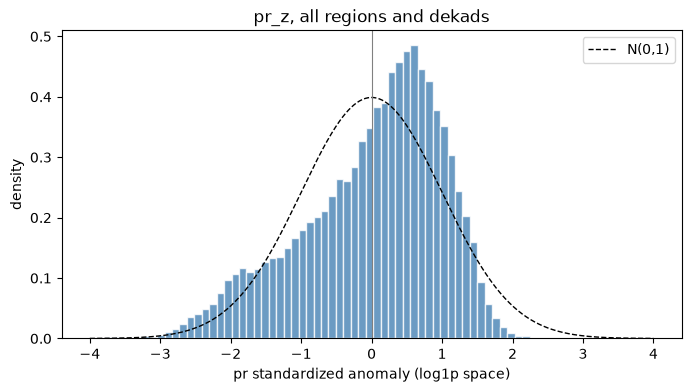

n = 71100, min = -3.89, max = 2.45
skewness = -0.68


In [ ]:
# check histogramm for standardized pr
# confirm log1p transform improved skew

# code by ChatGPT
z = pr_z["pr_z"]

vals = z.values.ravel()
vals = vals[np.isfinite(vals)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=60, density=True, color="steelblue", alpha=0.8, edgecolor="white")

# reference: standard normal curve
x = np.linspace(-4, 4, 400)
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="N(0,1)")

ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("pr standardized anomaly (log1p space)")
ax.set_ylabel("density")
ax.set_title("pr_z, all regions and dekads")
ax.legend()
plt.show()

print(f"n = {vals.size}, min = {vals.min():.2f}, max = {vals.max():.2f}")
print(f"skewness = {((vals - vals.mean())**3).mean() / vals.std()**3:.2f}")

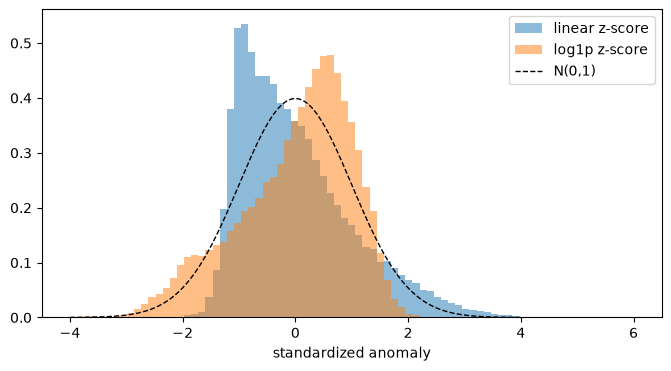

n = 71100, min = 0.00, max = 179.61
skewness = 2.11


In [19]:
# compare to untransformed raw pr values
# code for plot by ChatGPT
pr_dek = xr.open_dataarray("../data/processed/pr_sum_dekadal_natraum_2001_2025.nc")
mu = pr_dek.mean("year")
sd = pr_dek.std("year", ddof=0)
z_lin = ((pr_dek - mu) / sd).values.ravel()
z_lin = z_lin[np.isfinite(z_lin)]

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-4, 6, 80)
ax.hist(z_lin, bins=bins, density=True, alpha=0.5, label="linear z-score")
ax.hist(vals, bins=bins, density=True, alpha=0.5, label="log1p z-score")
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="N(0,1)")
ax.legend()
ax.set_xlabel("standardized anomaly")
plt.show()

vals = pr_dek.values.ravel()
vals = vals[np.isfinite(vals)]

print(f"n = {vals.size}, min = {vals.min():.2f}, max = {vals.max():.2f}")
print(f"skewness = {((vals - vals.mean())**3).mean() / vals.std()**3:.2f}")

In [18]:
z = pr_z["pr_z"]
extreme = z.where(z < -3)

# count of extreme-dry cells per month
print(extreme.notnull().sum(dim=["region_id", "year", "dekad"]).to_series())

# and which years
print(extreme.notnull().sum(dim=["region_id", "month", "dekad"]).to_series())

month
1     114
2       0
3       0
4       0
5       6
6      13
7       8
8       4
9       0
10     10
11      0
12      1
Name: pr_z, dtype: int64
year
2001      0
2002      2
2003      1
2004      1
2005      0
2006    114
2007      1
2008      0
2009      0
2010     10
2011      0
2012      0
2013      2
2014      2
2015      0
2016      0
2017      0
2018     11
2019      1
2020      0
2021      1
2022      4
2023      6
2024      0
2025      0
Name: pr_z, dtype: int64


In [21]:
dtr_z.var

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 570kB
Dimensions:    (region_id: 79, year: 25, month: 12, dekad: 3)
Coordinates:
  * region_id  (region_id) int64 632B 1 2 3 4 5 6 7 8 ... 73 74 75 76 77 78 79
  * year       (year) int32 100B 2001 2002 2003 2004 ... 2022 2023 2024 2025
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Data variables:
    dtr_z      (region_id, year, month, dekad) float64 569kB ...>

## Correlation analysis between features

In [ ]:
feat_cols = list(feature_ds.data_vars)

ml_df = feature_ds.to_dataframe().reset_index().dropna(subset=feat_cols).reset_index(drop=True)
X = ml_df[feat_cols]
print(X.shape)    # looks right!

(70863, 9)


In [29]:
corr = X.corr()                      # Pearson correlation
print(corr)


                   pr_z  pr3dek_z  drydays_z     tas_z     dtr_z   smtop_z  \
pr_z           1.000000  0.552036  -0.828797 -0.066344 -0.453978  0.532581   
pr3dek_z       0.552036  1.000000  -0.488052 -0.095100 -0.390802  0.755573   
drydays_z     -0.828797 -0.488052   1.000000  0.108496  0.467002 -0.497189   
tas_z         -0.066344 -0.095100   0.108496  1.000000  0.361099 -0.176282   
dtr_z         -0.453978 -0.390802   0.467002  0.361099  1.000000 -0.474132   
smtop_z        0.532581  0.755573  -0.497189 -0.176282 -0.474132  1.000000   
smtop_trend_z  0.492554  0.660141  -0.459275 -0.081814 -0.375138  0.557163   
smmid_z        0.018203  0.179099  -0.024598 -0.147061 -0.149203  0.403217   
smlow_z       -0.004926  0.019954   0.003040 -0.092113 -0.061032  0.152172   

               smtop_trend_z   smmid_z   smlow_z  
pr_z                0.492554  0.018203 -0.004926  
pr3dek_z            0.660141  0.179099  0.019954  
drydays_z          -0.459275 -0.024598  0.003040  
tas_z          

In [ ]:
corr_s = X.corr(method="spearman")   # robust to the skew in the precipitation features
print(corr_s)

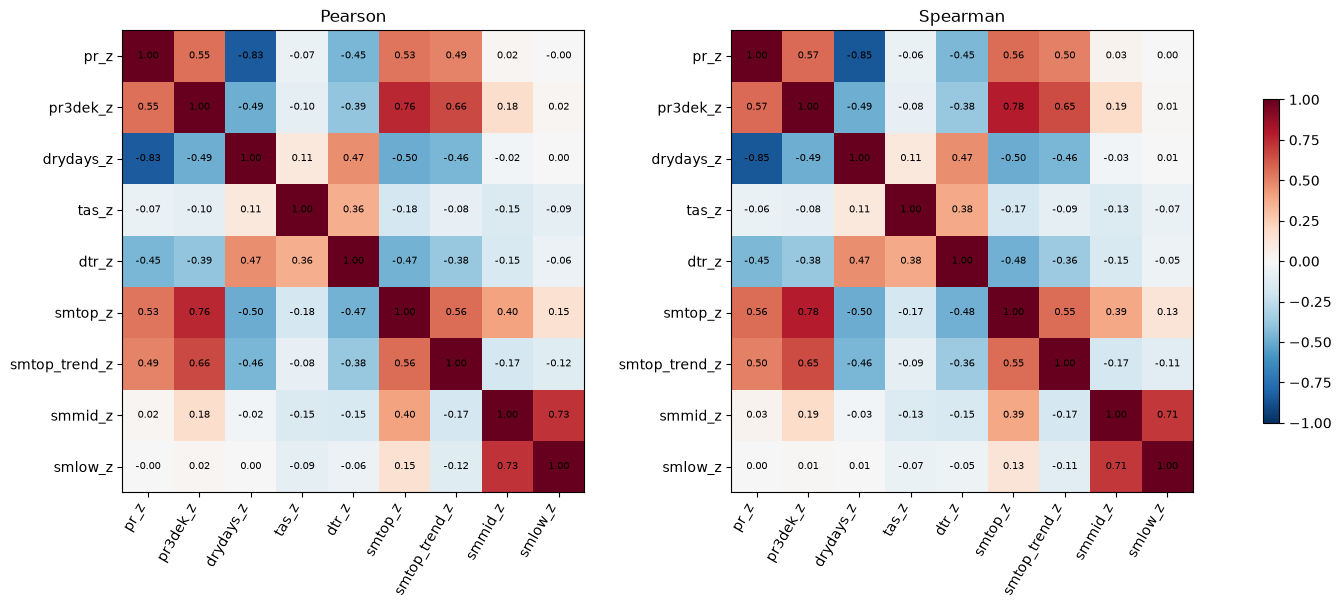

   feature_1  feature_2         r
2       pr_z  drydays_z -0.828797
14  pr3dek_z    smtop_z  0.755573
71   smmid_z    smlow_z  0.725363


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, c, title in zip(axes, [corr, corr_s], ["Pearson", "Spearman"]):
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=60, ha="right")
    ax.set_yticks(range(len(feat_cols)), feat_cols)
    for i in range(len(feat_cols)):
        for j in range(len(feat_cols)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

# flag the strong pairs
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().rename("r").reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
print(pairs[pairs["r"].abs() > 0.7].sort_values("r", key=abs, ascending=False))

In [34]:
# corr of just summer months
summer = ml_df[ml_df["month"].between(5, 9)]
print(summer[feat_cols].corr().round(2))

               pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  \
pr_z           1.00      0.54      -0.80  -0.31  -0.59     0.51   
pr3dek_z       0.54      1.00      -0.48  -0.32  -0.51     0.79   
drydays_z     -0.80     -0.48       1.00   0.41   0.64    -0.47   
tas_z         -0.31     -0.32       0.41   1.00   0.62    -0.40   
dtr_z         -0.59     -0.51       0.64   0.62   1.00    -0.62   
smtop_z        0.51      0.79      -0.47  -0.40  -0.62     1.00   
smtop_trend_z  0.47      0.68      -0.44  -0.32  -0.48     0.62   
smmid_z        0.05      0.24      -0.05  -0.11  -0.23     0.50   
smlow_z        0.01      0.03      -0.01  -0.01  -0.11     0.16   

               smtop_trend_z  smmid_z  smlow_z  
pr_z                    0.47     0.05     0.01  
pr3dek_z                0.68     0.24     0.03  
drydays_z              -0.44    -0.05    -0.01  
tas_z                  -0.32    -0.11    -0.01  
dtr_z                  -0.48    -0.23    -0.11  
smtop_z                 0.62     0.

## PCA

   PC  explained  cumulative
0   1      0.418       0.418
1   2      0.209       0.626
2   3      0.119       0.745
3   4      0.092       0.837
4   5      0.055       0.892
5   6      0.050       0.942
6   7      0.025       0.967
7   8      0.018       0.985
8   9      0.015       1.000


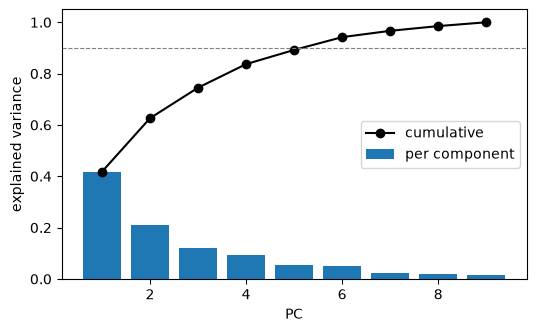

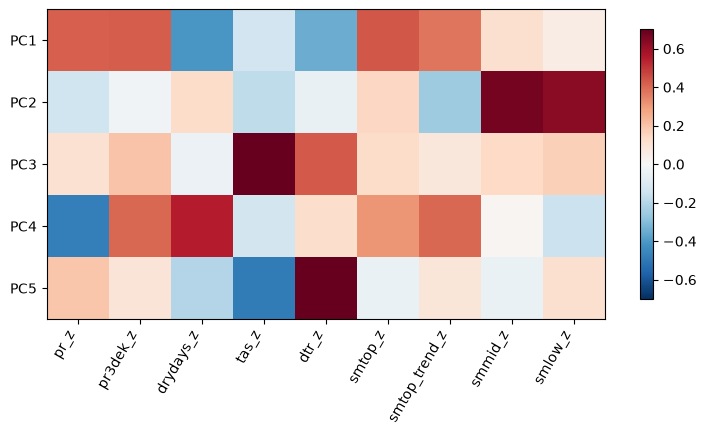

     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
PC1  0.42      0.42      -0.41  -0.13  -0.35     0.43           0.37     0.11   
PC2 -0.14     -0.03       0.13  -0.18  -0.05     0.14          -0.25     0.67   
PC3  0.11      0.20      -0.04   0.83   0.43     0.13           0.08     0.14   
PC4 -0.48      0.40       0.55  -0.13   0.13     0.31           0.40     0.01   

     smlow_z  
PC1     0.05  
PC2     0.63  
PC3     0.16  
PC4    -0.15  


In [36]:
Xs = StandardScaler().fit_transform(X)       # almost a no-op, features are already z-scores
pca = PCA().fit(Xs)

evr = pca.explained_variance_ratio_
print(pd.DataFrame({"PC": range(1, len(evr) + 1),
                    "explained": evr.round(3),
                    "cumulative": evr.cumsum().round(3)}))

# scree plot
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(1, len(evr) + 1), evr, label="per component")
ax.plot(range(1, len(evr) + 1), evr.cumsum(), "ko-", label="cumulative")
ax.axhline(0.9, color="grey", ls="--", lw=0.8)
ax.set_xlabel("PC"); ax.set_ylabel("explained variance"); ax.legend()
plt.show()

# loadings, one row per PC
loadings = pd.DataFrame(pca.components_, columns=feat_cols,
                        index=[f"PC{i+1}" for i in range(len(feat_cols))])
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(loadings.iloc[:5], cmap="RdBu_r", vmin=-0.7, vmax=0.7)    # first 5 PCs
ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=60, ha="right")
ax.set_yticks(range(5), loadings.index[:5])
fig.colorbar(im, shrink=0.7)
plt.show()
print(loadings.iloc[:4].round(2))